# Difração — análise experimental

Notebook acadêmico para analisar dados de difração, ajustar relações lineares e visualizar resultados experimentais com NumPy, Matplotlib e SciPy.

Os valores experimentais utilizados estão definidos no próprio notebook. Execute as células em ordem e confira as hipóteses e unidades antes de reutilizar os resultados.

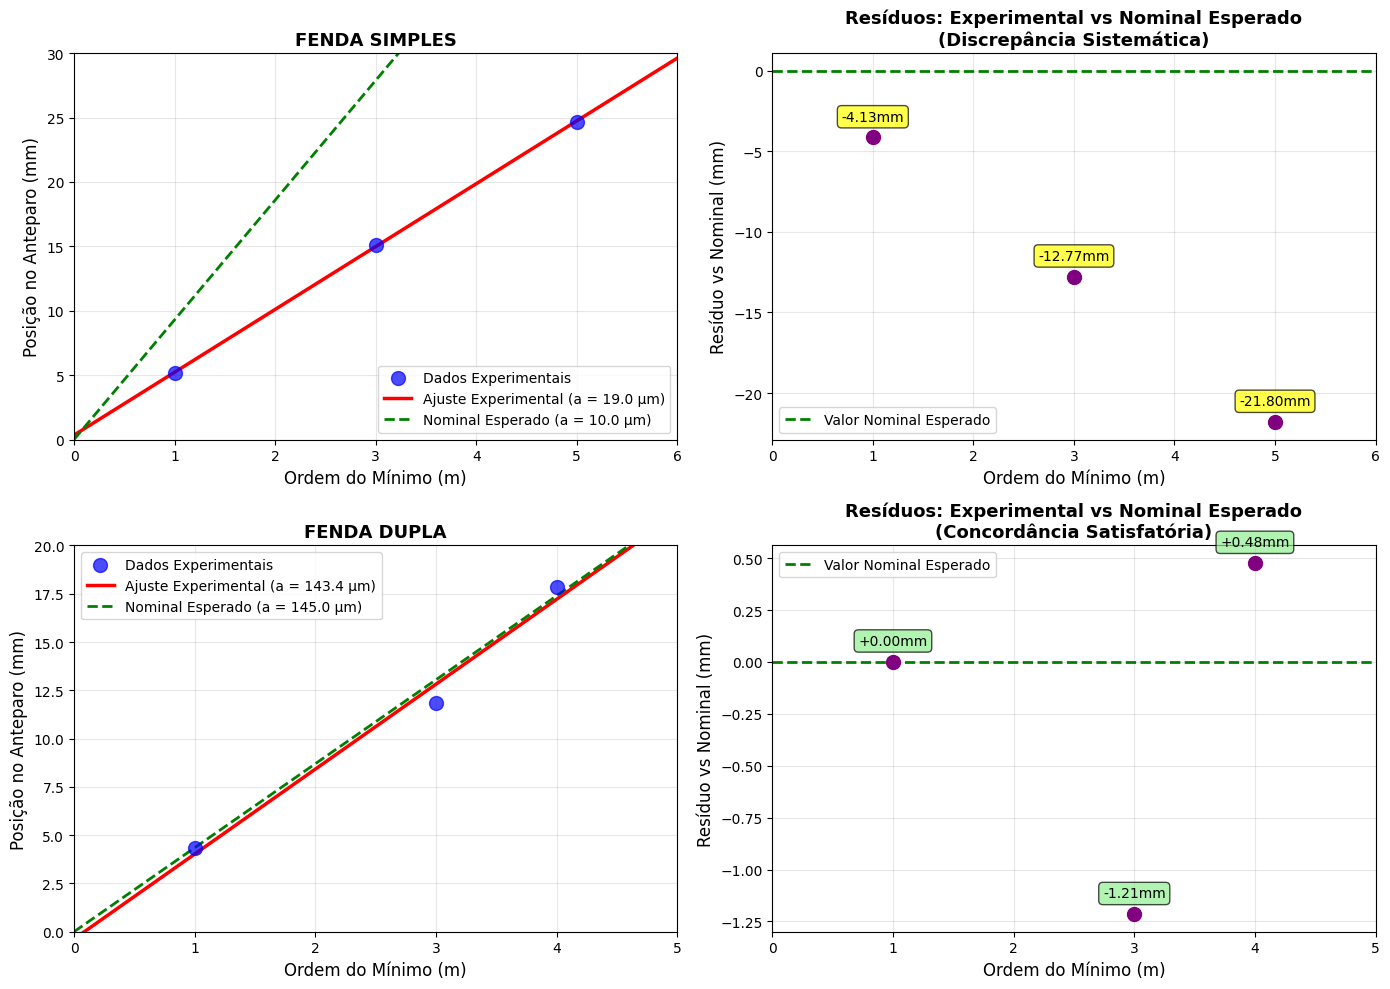

ANÁLISE DA DISCREPÂNCIA - FENDA SIMPLES
Largura Experimental: 19.0 μm
Largura Nominal: 10.0 μm
Discrepância: 9.0 μm (90%)
✓ Ajuste linear excelente (R² = 0.9999) → medidas consistentes
✗ Discrepância grande com valor nominal → problema sistemático

POSSÍVEIS CAUSAS:
1. Fenda realmente tem ≈18 μm (erro de fabricação/especificação)
2. Identificação incorreta inicial das ordens de difração
3. Erro sistemático na medida de D ou λ

ANÁLISE DA CONCORDÂNCIA - FENDA DUPLA
Largura Experimental: 143.4 μm
Largura Nominal: 145.0 μm
Diferença: 1.6 μm (1.1%)
✓ Ajuste linear muito bom (R² = 0.9835)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Configuração do estilo
plt.style.use('default')
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

# ============================================================================
# FENDA SIMPLES - Análise Completa
# ============================================================================

m_simples = np.array([1, 3, 5])
y_exp_simples = np.array([5.16, 15.11, 24.68])

# Ajuste linear experimental
slope_simples, intercept_simples, r_value_simples, _, _ = stats.linregress(m_simples, y_exp_simples)
y_teorico_simples = slope_simples * m_simples + intercept_simples
residuos_simples = y_exp_simples - y_teorico_simples

# Cálculo da largura experimental
a_exp_simples = 0.65 * 143 / slope_simples  # λ = 0.65 μm, D = 143 mm

# VALOR QUE DEVERÍAMOS TER se a fenda tivesse 10 μm
slope_nominal_simples = 0.65 * 143 / 10.0  # Para a = 10 μm
y_nominal_simples = slope_nominal_simples * m_simples

# Gráfico de ajuste - Fenda Simples (COMPARATIVO)
ax1.scatter(m_simples, y_exp_simples, color='blue', s=100, label='Dados Experimentais', zorder=5, alpha=0.7)
m_line = np.linspace(0, 6, 100)

# Linha do ajuste experimental
ax1.plot(m_line, slope_simples * m_line + intercept_simples, color='red', linewidth=2.5,
         label=f'Ajuste Experimental (a = {a_exp_simples:.1f} μm)')

# Linha do valor nominal esperado
ax1.plot(m_line, slope_nominal_simples * m_line, color='green', linestyle='--', linewidth=2,
         label=f'Nominal Esperado (a = 10.0 μm)')

ax1.set_xlabel('Ordem do Mínimo (m)', fontsize=12)
ax1.set_ylabel('Posição no Anteparo (mm)', fontsize=12)
ax1.set_title('FENDA SIMPLES', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend()
ax1.set_xlim(0, 6)
ax1.set_ylim(0, 30)

# Gráfico de resíduos vs nominal
residuos_vs_nominal = y_exp_simples - y_nominal_simples
ax2.scatter(m_simples, residuos_vs_nominal, color='purple', s=100, zorder=5)
ax2.axhline(y=0, color='green', linestyle='--', linewidth=2, label='Valor Nominal Esperado')
ax2.set_xlabel('Ordem do Mínimo (m)', fontsize=12)
ax2.set_ylabel('Resíduo vs Nominal (mm)', fontsize=12)
ax2.set_title(f'Resíduos: Experimental vs Nominal Esperado\n(Discrepância Sistemática)', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend()
ax2.set_xlim(0, 6)

for i, (m, res) in enumerate(zip(m_simples, residuos_vs_nominal)):
    ax2.annotate(f'{res:+.2f}mm', (m, res), textcoords="offset points", xytext=(0,12), ha='center', fontsize=10,
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="yellow", alpha=0.7))

# ============================================================================
# FENDA DUPLA - Análise Completa
# ============================================================================

m_dupla = np.array([1, 3, 4])
y_exp_dupla = np.array([4.35, 11.83, 17.87])

# Ajuste linear experimental
slope_dupla, intercept_dupla, r_value_dupla, _, _ = stats.linregress(m_dupla, y_exp_dupla)

# Cálculo da largura experimental
a_exp_dupla = 0.65 * 970 / slope_dupla  # λ = 0.65 μm, D = 970 mm

# VALOR QUE DEVERÍAMOS TER se a fenda tivesse 145 μm
slope_nominal_dupla = 0.65 * 970 / 145.0  # Para a = 145 μm
y_nominal_dupla = slope_nominal_dupla * m_dupla

# Gráfico de ajuste - Fenda Dupla (COMPARATIVO)
ax3.scatter(m_dupla, y_exp_dupla, color='blue', s=100, label='Dados Experimentais', zorder=5, alpha=0.7)

# Linha do ajuste experimental
ax3.plot(m_line, slope_dupla * m_line + intercept_dupla, color='red', linewidth=2.5,
         label=f'Ajuste Experimental (a = {a_exp_dupla:.1f} μm)')

# Linha do valor nominal esperado
ax3.plot(m_line, slope_nominal_dupla * m_line, color='green', linestyle='--', linewidth=2,
         label=f'Nominal Esperado (a = 145.0 μm)')

ax3.set_xlabel('Ordem do Mínimo (m)', fontsize=12)
ax3.set_ylabel('Posição no Anteparo (mm)', fontsize=12)
ax3.set_title('FENDA DUPLA', fontsize=13, fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.legend()
ax3.set_xlim(0, 5)
ax3.set_ylim(0, 20)

# Gráfico de resíduos vs nominal - Fenda Dupla
residuos_vs_nominal_dupla = y_exp_dupla - y_nominal_dupla
ax4.scatter(m_dupla, residuos_vs_nominal_dupla, color='purple', s=100, zorder=5)
ax4.axhline(y=0, color='green', linestyle='--', linewidth=2, label='Valor Nominal Esperado')
ax4.set_xlabel('Ordem do Mínimo (m)', fontsize=12)
ax4.set_ylabel('Resíduo vs Nominal (mm)', fontsize=12)
ax4.set_title(f'Resíduos: Experimental vs Nominal Esperado\n(Concordância Satisfatória)', fontsize=13, fontweight='bold')
ax4.grid(True, alpha=0.3)
ax4.legend()
ax4.set_xlim(0, 5)

for i, (m, res) in enumerate(zip(m_dupla, residuos_vs_nominal_dupla)):
    ax4.annotate(f'{res:+.2f}mm', (m, res), textcoords="offset points", xytext=(0,12), ha='center', fontsize=10,
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgreen", alpha=0.7))

# ============================================================================
# ANÁLISE FINAL
# ============================================================================

plt.tight_layout()
plt.show()

print("="*70)
print("ANÁLISE DA DISCREPÂNCIA - FENDA SIMPLES")
print("="*70)
print(f"Largura Experimental: {a_exp_simples:.1f} μm")
print(f"Largura Nominal: 10.0 μm")
print(f"Discrepância: {abs(a_exp_simples - 10.0):.1f} μm ({abs((a_exp_simples - 10.0)/10.0)*100:.0f}%)")
print(f"✓ Ajuste linear excelente (R² = {r_value_simples**2:.4f}) → medidas consistentes")
print(f"✗ Discrepância grande com valor nominal → problema sistemático")
print("\nPOSSÍVEIS CAUSAS:")
print("1. Fenda realmente tem ≈18 μm (erro de fabricação/especificação)")
print("2. Identificação incorreta inicial das ordens de difração")
print("3. Erro sistemático na medida de D ou λ")

print("\n" + "="*70)
print("ANÁLISE DA CONCORDÂNCIA - FENDA DUPLA")
print("="*70)
print(f"Largura Experimental: {a_exp_dupla:.1f} μm")
print(f"Largura Nominal: 145.0 μm")
print(f"Diferença: {abs(a_exp_dupla - 145.0):.1f} μm ({abs((a_exp_dupla - 145.0)/145.0)*100:.1f}%)")
print(f"✓ Ajuste linear muito bom (R² = {r_value_dupla**2:.4f})")
